# Nhiệm vụ 1: Học không giám sát & Giảm chiều dữ liệu (PCA)

Dữ liệu: `cgv_eda_cleaned.csv` (kết quả của bước EDA).

Các bước:
1. Chuẩn bị đặc trưng (số + đặc trưng suy ra + mã hóa biến phân loại)
2. **Chuẩn hóa đặc trưng** bằng `StandardScaler` (so sánh thêm với `MinMaxScaler`)
3. **Chọn số thành phần** theo Cumulative Explained Variance Ratio (giữ 85% – 95% phương sai)
4. **Đầu ra trực quan**: biểu đồ phương sai dạng khuỷu tay (Elbow-style) và biểu đồ phân tán 2D/3D

## 1. Đọc dữ liệu

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA

plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42

df = pd.read_csv("cgv_eda_cleaned.csv", encoding="utf-8-sig")
print("Số dòng:", len(df))
print("Số cột:", len(df.columns))
print("Tổng giá trị thiếu:", int(df.isna().sum().sum()))
df.head()

Số dòng: 1172
Số cột: 18
Tổng giá trị thiếu: 0


,MovieName,Cinema,ShowDate,Format,ShowTime,GeneratedText,TicketPrice,AvailableSeats,TotalSeats,MovieURL,Rating,Director,Actors,Genre,ReleaseDate,Duration,Language,DurationMinutes
0,AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT (CHIẾU ...,CGV Crescent Mall,2026-10-01,2D Phụ Đề Việt | Rạp Lamour,10:30,Tôi đã có cơ hội xem suất chiếu AVENGERS: HỒI ...,70000,80,100,https://www.cgv.vn/default/avengers-endgame-en...,T13,"Anthony Russo, Joe Russo","Robert Downey Jr., Chris Evans, Mark Ruffalo, ...","Hành Động, Khoa Học Viễn Tưởng, Phiêu Lưu",2026-09-25,183 phút,Tiếng Anh với phụ đề tiếng Việt,183.0
1,AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT (CHIẾU ...,CGV Crescent Mall,2026-10-01,2D Phụ Đề Việt | Rạp Lamour,16:00,"Hôm nay, tôi có cơ hội tham gia vào một trải n...",100000,90,100,https://www.cgv.vn/default/avengers-endgame-en...,T13,"Anthony Russo, Joe Russo","Robert Downey Jr., Chris Evans, Mark Ruffalo, ...","Hành Động, Khoa Học Viễn Tưởng, Phiêu Lưu",2026-09-25,183 phút,Tiếng Anh với phụ đề tiếng Việt,183.0
2,AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT (CHIẾU ...,CGV Crescent Mall,2026-10-01,2D Phụ Đề Việt | Rạp Lamour,21:30,Tôi đã có cơ hội xem suất chiếu AVENGERS: HỒI ...,90000,80,100,https://www.cgv.vn/default/avengers-endgame-en...,T13,"Anthony Russo, Joe Russo","Robert Downey Jr., Chris Evans, Mark Ruffalo, ...","Hành Động, Khoa Học Viễn Tưởng, Phiêu Lưu",2026-09-25,183 phút,Tiếng Anh với phụ đề tiếng Việt,183.0
3,CHIIKAWA: BÍ MẬT ĐẢO NGƯỜI CÁ,CGV Crescent Mall,2026-10-01,2D Phụ Đề Anh & Việt,18:00,"Hôm nay, tôi đã có cơ hội đến rạp chiếu CGV Cr...",80000,90,100,https://www.cgv.vn/default/chiikawa-the-movie....,p,Kei Oikawa,"Haruka Aoki, Makoto Tanaka, Ari Ozawa, Yuka Ig...",Hoạt Hình,2026-08-28,99 phút,Tiếng Nhật với phụ đề Việt & Anh; Lồng tiếng Việt,99.0
4,HÒN ĐẢO QUÊN LÃNG,CGV Crescent Mall,2026-10-01,2D Lồng Tiếng Việt,19:40,"Tôi vừa có cơ hội xem suất chiếu ""HÒN ĐẢO QUÊN...",100000,50,80,https://www.cgv.vn/default/forgotten-island.html,K,Joel Crawford; Januel Mercado,"H.E.R., Liza Soberano, Dave Franco, Jenny Slat...","Hoạt Hình, Phiêu Lưu",2026-09-25,109 phút,Phụ đề Tiếng Việt & Lồng Tiếng Việt,109.0


## 2. Chuẩn bị ma trận đặc trưng

PCA chỉ làm việc với dữ liệu số, nên:
- **Đặc trưng số gốc:** `TicketPrice`, `AvailableSeats`, `TotalSeats`, `DurationMinutes`.
- **Đặc trưng suy ra:** `OccupancyRate` (tỉ lệ lấp đầy), `ShowHour` (giờ chiếu), `DaysSinceRelease` (số ngày từ lúc phát hành đến suất chiếu), `IsWeekend`, `IsPremiumRoom` (phòng đặc biệt như IMAX, 4DX, GOLD CLASS...).
- **Biến phân loại → số:** one-hot cho `Cinema`, `Rating`, loại định dạng chiếu (`FormatTech`); multi-hot cho `Genre`.
- Bỏ các cột văn bản/định danh không phù hợp PCA: `MovieName`, `GeneratedText`, `MovieURL`, `Director`, `Actors`, `Language`, `Duration` (đã có `DurationMinutes`).

In [3]:
feat = pd.DataFrame(index=df.index)

# --- Đặc trưng số gốc ---
num_cols = ["TicketPrice", "AvailableSeats", "TotalSeats", "DurationMinutes"]
for col in num_cols:
    feat[col] = pd.to_numeric(df[col], errors="coerce")

# --- Đặc trưng suy ra ---
feat["OccupancyRate"] = (df["TotalSeats"] - df["AvailableSeats"]) / df["TotalSeats"]
feat["ShowHour"] = pd.to_datetime(df["ShowTime"], format="%H:%M", errors="coerce").dt.hour \
                   + pd.to_datetime(df["ShowTime"], format="%H:%M", errors="coerce").dt.minute / 60

show_date = pd.to_datetime(df["ShowDate"], format="%Y-%m-%d", errors="coerce")
release_date = pd.to_datetime(df["ReleaseDate"], format="%Y-%m-%d", errors="coerce")
feat["DaysSinceRelease"] = (show_date - release_date).dt.days
feat["IsWeekend"] = (show_date.dt.dayofweek >= 5).astype(int)

# Format: tách loại công nghệ (2D, IMAX2D, 4DX2D...) và cờ phòng đặc biệt (có "| Rạp ...")
fmt = df["Format"].astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
df["FormatTech"] = fmt.str.split(r" Phụ| Lồng", n=1, regex=True).str[0].str.strip()
feat["IsPremiumRoom"] = fmt.str.contains(r"\|", regex=True).astype(int)

# --- Biến phân loại -> số ---
cat_dummies = pd.get_dummies(df[["Cinema", "Rating", "FormatTech"]], dtype=int)
genre_dummies = df["Genre"].str.get_dummies(sep=", ").add_prefix("Genre_")

X = pd.concat([feat, cat_dummies, genre_dummies], axis=1)

print("Số đặc trưng:", X.shape[1])
print("Giá trị thiếu trong X:", int(X.isna().sum().sum()))
X.head()

Số đặc trưng: 33
Giá trị thiếu trong X: 0


,TicketPrice,AvailableSeats,TotalSeats,DurationMinutes,OccupancyRate,ShowHour,DaysSinceRelease,IsWeekend,IsPremiumRoom,Cinema_CGV Crescent Mall,...,Genre_Gia đình,Genre_Hoạt Hình,Genre_Hài,Genre_Hành Động,Genre_Hồi hộp,Genre_Khoa Học Viễn Tưởng,Genre_Kinh Dị,Genre_Phiêu Lưu,Genre_Thần thoại,Genre_Tâm Lý
0,70000,80,100,183.0,0.200,10.500000,6,0,1,1,...,0,0,0,1,0,1,0,1,0,0
1,100000,90,100,183.0,0.100,16.000000,6,0,1,1,...,0,0,0,1,0,1,0,1,0,0
2,90000,80,100,183.0,0.200,21.500000,6,0,1,1,...,0,0,0,1,0,1,0,1,0,0
3,80000,90,100,99.0,0.100,18.000000,34,0,0,1,...,0,1,0,0,0,0,0,0,0,0
4,100000,50,80,109.0,0.375,19.666667,6,0,0,1,...,0,1,0,0,0,0,0,1,0,0


In [4]:
# Kiểm tra nhanh: đặc trưng không đổi (phương sai = 0) không mang thông tin cho PCA
zero_var = X.columns[X.var() == 0].tolist()
print("Đặc trưng phương sai = 0:", zero_var)
X = X.drop(columns=zero_var)
print("Số đặc trưng dùng cho PCA:", X.shape[1])

Đặc trưng phương sai = 0: []
Số đặc trưng dùng cho PCA: 33


## 3. Chuẩn hóa đặc trưng (Feature Scaling)

PCA dựa trên phương sai, nên đặc trưng có thang đo lớn (ví dụ `TicketPrice` ~ 100.000) sẽ lấn át các đặc trưng nhỏ (ví dụ cờ 0/1). Vì vậy cần chuẩn hóa trước khi huấn luyện PCA.

Dùng **`StandardScaler`** làm phương án chính (mean = 0, std = 1).

In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Kích thước:", X_scaled.shape)
print("Trung bình sau chuẩn hóa (tối đa |mean|):", np.abs(X_scaled.mean(axis=0)).max().round(6))
print("Độ lệch chuẩn sau chuẩn hóa (min / max):",
      X_scaled.std(axis=0).min().round(3), "/", X_scaled.std(axis=0).max().round(3))

Kích thước: (1172, 33)
Trung bình sau chuẩn hóa (tối đa |mean|): 0.0
Độ lệch chuẩn sau chuẩn hóa (min / max): 1.0 / 1.0


## 4. Lựa chọn thành phần (Component Selection)

Huấn luyện PCA với toàn bộ thành phần, sau đó tính **Cumulative Explained Variance Ratio**.

In [6]:
pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X_scaled)

explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)

var_table = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(explained))],
    "Explained_Variance_Ratio": explained,
    "Cumulative_Ratio": cumulative,
})
var_table.head(15).round(4)

,Component,Explained_Variance_Ratio,Cumulative_Ratio
0,PC1,0.1557,0.1557
1,PC2,0.1209,0.2766
2,PC3,0.0877,0.3642
3,PC4,0.0614,0.4256
4,PC5,0.0604,0.4860
5,PC6,0.0549,0.5409
6,PC7,0.0473,0.5882
7,PC8,0.0443,0.6326
8,PC9,0.0416,0.6741
9,PC10,0.0395,0.7137


In [7]:
# Số thành phần tối thiểu để giữ lại 85% - 95% phương sai
thresholds = [0.85, 0.90, 0.95]
n_needed = {t: int(np.argmax(cumulative >= t) + 1) for t in thresholds}

for t, n in n_needed.items():
    print(f"Giữ >= {t:.0%} phương sai: cần {n} thành phần (thực tế {cumulative[n-1]:.2%})")

# Chọn ngưỡng 90% (nằm giữa khoảng 85% - 95%)
TARGET = 0.90
n_components = n_needed[TARGET]
print(f"\n=> Chọn n_components = {n_components} (giữ {cumulative[n_components-1]:.2%} phương sai, "
      f"giảm từ {X_scaled.shape[1]} xuống {n_components} chiều)")

Giữ >= 85% phương sai: cần 15 thành phần (thực tế 86.93%)
Giữ >= 90% phương sai: cần 17 thành phần (thực tế 91.83%)
Giữ >= 95% phương sai: cần 19 thành phần (thực tế 96.07%)

=> Chọn n_components = 17 (giữ 91.83% phương sai, giảm từ 33 xuống 17 chiều)


In [8]:
# Huấn luyện lại PCA với số thành phần đã chọn
pca = PCA(n_components=n_components, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(X_pca, columns=[f"PC{i+1}" for i in range(n_components)])
print("Kích thước sau PCA:", X_pca.shape)
print("Tổng phương sai giữ lại:", pca.explained_variance_ratio_.sum().round(4))
pca_df.head()

Kích thước sau PCA: (1172, 17)
Tổng phương sai giữ lại: 0.9183


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16,PC17
0,3.947505,-0.849205,0.704069,-0.376111,0.770505,-2.228207,-1.312945,0.640157,-1.926192,1.747161,-0.894755,-0.466680,-0.195070,-1.028160,-1.544128,-1.304589,-0.091267
1,4.146341,-0.917851,0.788019,0.473539,0.865614,-2.639617,-0.910327,0.299679,-1.743787,1.721411,-0.251172,0.146534,0.030236,0.427790,0.617800,0.053445,-0.506922
2,4.107294,-0.801247,0.934412,-0.628286,0.994100,-2.121786,-0.903987,0.361589,-1.563364,1.759292,-0.429106,0.617394,0.850532,0.458606,-0.637933,0.451673,-0.160074
3,-2.806566,-3.788726,-2.209508,1.180945,3.090163,-0.902013,2.142926,0.095426,-1.720898,2.357941,4.097752,-2.101397,-0.270348,4.217609,-2.951055,-2.326912,0.945685
4,-0.418981,-2.959733,-1.736814,-3.282781,-0.317583,1.763478,-0.809195,0.934142,-1.234827,2.068403,-1.479256,-0.704638,0.114568,0.757045,0.123915,2.370109,-0.574462


## 5. Đầu ra trực quan

### 5.1. Biểu đồ phương sai dạng khuỷu tay (Elbow-style)

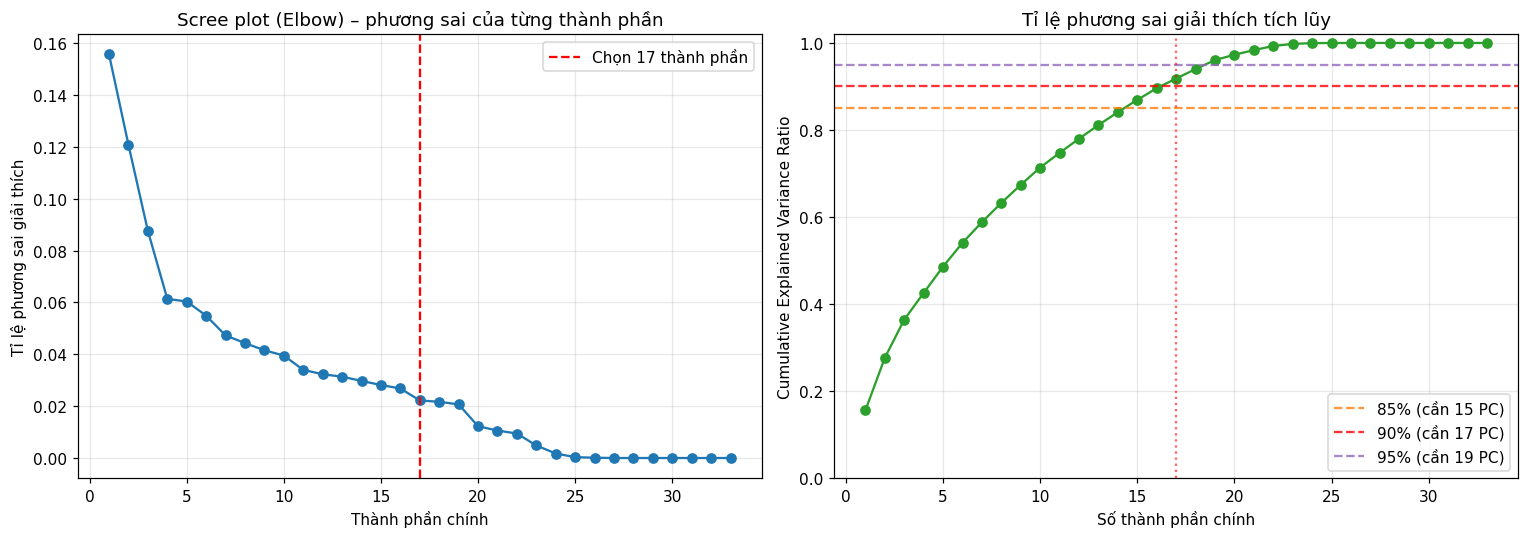

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (a) Scree / Elbow: phương sai giải thích của từng thành phần
x = np.arange(1, len(explained) + 1)
axes[0].plot(x, explained, marker="o", color="#1f77b4")
axes[0].axvline(n_components, color="red", linestyle="--", label=f"Chọn {n_components} thành phần")
axes[0].set_title("Scree plot (Elbow) – phương sai của từng thành phần")
axes[0].set_xlabel("Thành phần chính")
axes[0].set_ylabel("Tỉ lệ phương sai giải thích")
axes[0].legend()
axes[0].grid(alpha=0.3)

# (b) Phương sai tích lũy với các ngưỡng 85% / 90% / 95%
axes[1].plot(x, cumulative, marker="o", color="#2ca02c")
for t, col in zip(thresholds, ["#ff7f0e", "red", "#9467bd"]):
    axes[1].axhline(t, color=col, linestyle="--", alpha=0.8, label=f"{t:.0%} (cần {n_needed[t]} PC)")
axes[1].axvline(n_components, color="red", linestyle=":", alpha=0.6)
axes[1].set_title("Tỉ lệ phương sai giải thích tích lũy")
axes[1].set_xlabel("Số thành phần chính")
axes[1].set_ylabel("Cumulative Explained Variance Ratio")
axes[1].set_ylim(0, 1.02)
axes[1].legend(loc="lower right")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 5.2. Biểu đồ phân tán 2D / 3D trong không gian thành phần chính

Màu điểm theo nhãn kiểm duyệt độ tuổi (`Rating`) để quan sát cách dữ liệu phân bố.

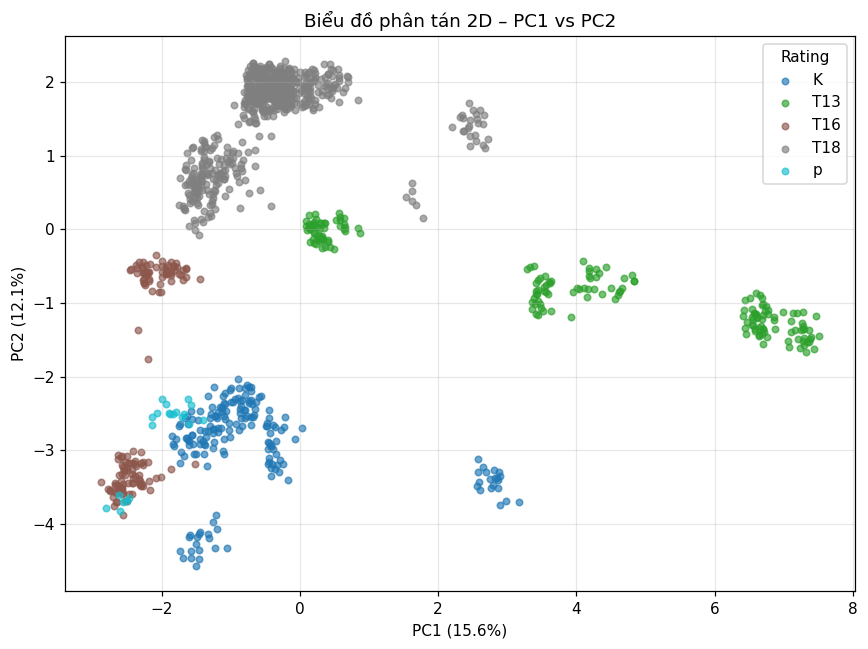

In [10]:
color_col = df["Rating"].astype(str)
categories = sorted(color_col.unique())
palette = dict(zip(categories, plt.cm.tab10(np.linspace(0, 1, len(categories)))))

fig, ax = plt.subplots(figsize=(8, 6))
for cat in categories:
    mask = (color_col == cat).values
    ax.scatter(pca_df.loc[mask, "PC1"], pca_df.loc[mask, "PC2"],
               s=18, alpha=0.65, color=palette[cat], label=cat)
ax.set_xlabel(f"PC1 ({explained[0]:.1%})")
ax.set_ylabel(f"PC2 ({explained[1]:.1%})")
ax.set_title("Biểu đồ phân tán 2D – PC1 vs PC2")
ax.legend(title="Rating")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

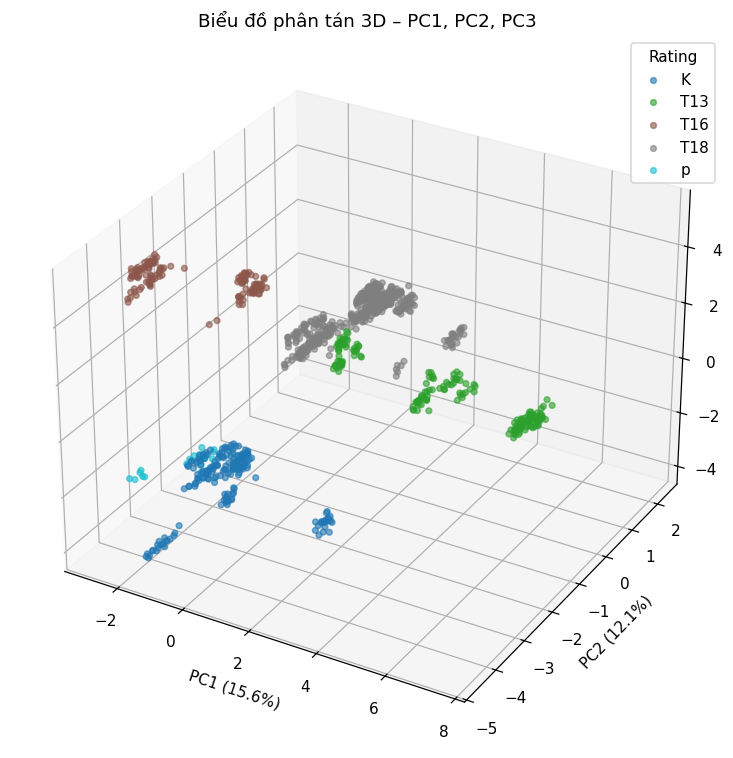

In [11]:
if n_components >= 3:
    fig = plt.figure(figsize=(9, 7))
    ax = fig.add_subplot(111, projection="3d")
    for cat in categories:
        mask = (color_col == cat).values
        ax.scatter(pca_df.loc[mask, "PC1"], pca_df.loc[mask, "PC2"], pca_df.loc[mask, "PC3"],
                   s=14, alpha=0.6, color=palette[cat], label=cat)
    ax.set_xlabel(f"PC1 ({explained[0]:.1%})")
    ax.set_ylabel(f"PC2 ({explained[1]:.1%})")
    ax.set_zlabel(f"PC3 ({explained[2]:.1%})")
    ax.set_title("Biểu đồ phân tán 3D – PC1, PC2, PC3")
    ax.legend(title="Rating")
    plt.tight_layout()
    plt.show()

### 5.3. Đặc trưng nào đóng góp nhiều nhất vào các thành phần chính?

In [12]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=X.columns,
    columns=[f"PC{i+1}" for i in range(n_components)],
)

for pc in ["PC1", "PC2", "PC3"]:
    if pc in loadings.columns:
        print(f"Top 5 đặc trưng ảnh hưởng nhất tới {pc}:")
        print(loadings[pc].reindex(loadings[pc].abs().sort_values(ascending=False).index).head(5).round(3))
        print()

Top 5 đặc trưng ảnh hưởng nhất tới PC1:
Genre_Khoa Học Viễn Tưởng    0.381
Genre_Phiêu Lưu              0.352
Rating_T13                   0.338
FormatTech_2D               -0.337
DurationMinutes              0.335
Name: PC1, dtype: float64

Top 5 đặc trưng ảnh hưởng nhất tới PC2:
Rating_T18         0.441
Genre_Hành Động    0.393
Genre_Hồi hộp      0.378
Genre_Hoạt Hình   -0.336
Rating_K          -0.316
Name: PC2, dtype: float64

Top 5 đặc trưng ảnh hưởng nhất tới PC3:
Rating_T16         0.449
Genre_Gia đình     0.432
Genre_Tâm Lý       0.432
Genre_Hoạt Hình   -0.375
Rating_K          -0.353
Name: PC3, dtype: float64



## 6. So sánh `StandardScaler` và `MinMaxScaler`

Yêu cầu cho phép dùng một trong hai bộ chuẩn hóa. Bảng dưới so sánh số thành phần cần thiết khi dùng từng loại.

In [13]:
rows = []
for name, sc in [("StandardScaler", StandardScaler()), ("MinMaxScaler", MinMaxScaler())]:
    Xs = sc.fit_transform(X)
    cum = np.cumsum(PCA(random_state=RANDOM_STATE).fit(Xs).explained_variance_ratio_)
    rows.append({"Scaler": name, **{f"Số PC cho {t:.0%}": int(np.argmax(cum >= t) + 1) for t in thresholds}})

pd.DataFrame(rows)

,Scaler,Số PC cho 85%,Số PC cho 90%,Số PC cho 95%
0,StandardScaler,15,17,19
1,MinMaxScaler,10,12,16


## 7. Kết luận

- Đã chuẩn hóa đặc trưng bằng `StandardScaler` trước khi huấn luyện PCA.
- Số thành phần tối thiểu để giữ lại 85% / 90% / 95% phương sai được tính từ Cumulative Explained Variance Ratio (xem ô kết quả ở mục 4); mô hình cuối dùng ngưỡng 90%.
- Dữ liệu sau PCA nằm trong `pca_df` (có thể dùng cho các bước học không giám sát tiếp theo như phân cụm).
- Các biểu đồ Elbow/Scree và scatter 2D/3D ở mục 5 thể hiện cấu trúc dữ liệu trong không gian thành phần chính mới.

In [14]:
# (Tùy chọn) Lưu dữ liệu sau PCA để dùng cho bước tiếp theo
pca_df.to_csv("cgv_pca_result.csv", index=False, encoding="utf-8-sig")
print("Đã lưu cgv_pca_result.csv")

Đã lưu cgv_pca_result.csv
